# **Assignment 3: From Clustering to Classification**
*Exploring Unsupervised and Supervised Learning with a Mystery Dataset*

**Objective:**
1. Unsupervised Learning: Apply clustering algorithms and dimensionality reduction techniques to uncover inherent patterns and structures within the dataset.
2. Supervised Learning: Once labels are introduced, transition to supervised learning by building and training a deep neural network model for classification.
3. Advanced Techniques and Comparison: Utilize techniques like hyperparameter tuning, model evaluation, and feature engineering to enhance model performance and compare unsupervised and supervised results.

**Dataset Overview:**

The dataset consists of 178 samples, each belonging to one of three distinct classes, representing unique groups with varying characteristics. Each sample includes 13 attributes capturing measurable properties related to chemical composition and structure.

The assignment is structured in two stages:

  **Stage 1.** Initially, treat the dataset as unlabeled and explore it using unsupervised learning techniques to reveal potential clusters and underlying patterns.

  **Stage 2:** Introduce the true labels and transition to supervised learning by building a classification model. This allows for performance evaluation and comparison of the clustering and classification outcomes.



# Part 1: Unsupervised Learning (Including Advanced Clustering)

**Objective**

Explore the dataset in assignment3_data.csv, using unsupervised learning techniques to identify inherent patterns and groupings without prior knowledge of the target labels.

**Step 1: Load the Dataset Without Labels**

**Instructions:**

1. Import the dataset from the provided CSV file, assignment3_data.csv.
2. Assign the loaded dataset to the expected variable step1_data for the autograder.
3. Confirm that you have successfully loaded the dataset by c hecking its structure (e.g., display the first few rows if needed).

In [71]:
# Import necessary library
import pandas as pd

# Load the dataset from 'assignment3_data.csv'
data = pd.read_csv('assignment3_data.csv')
print(data.head())
print('shape', data.shape)
print('columns', list(data.columns))
print('info', data.info)

# The following code is used by the autograder
step1_data = data


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

**Step 2: Exploratory Data Analysis (EDA)**

**Instructions:**

1. Calculate basic statistical metrics for the dataset, such as mean, median, min, and max values.
2. Check for missing values in the dataset and store the results in step2_missing_values.
3. Identify any potential outliers using Z-scores and store their indices in step2_outliers.
4. Use histograms to visualize the distribution of each feature in the dataset for a better understanding of the data's shape.

          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.9

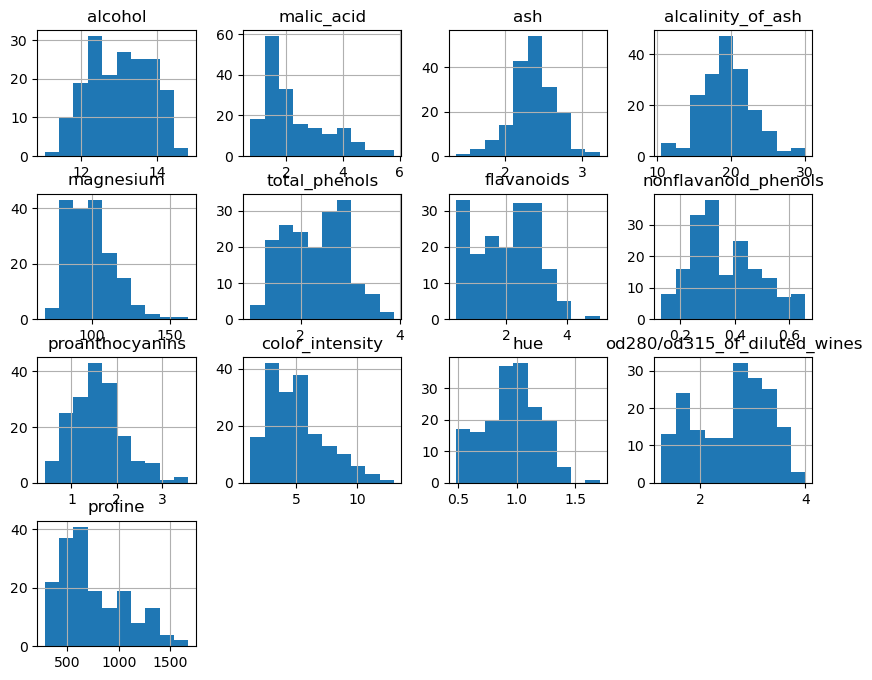

In [72]:
# Calculate basic statistics
step2_data_stats = data.describe()
print(step2_data_stats)

# Check for missing values
step2_missing_values = data.isnull().sum()

# Outlier detection using Z-scores
from scipy import stats
import numpy as np
# print('------')
# print(stats.zscore(data))
# print('------')
z_scores = np.abs(stats.zscore(data))
step2_outliers = np.where(z_scores>3)

print('missing values per column', step2_missing_values)
print('z score:\n', z_scores)
print('outlier indices', step2_outliers)


# Visualization (output not captured by autograder, but shown for EDA)
import matplotlib.pyplot as plt
import seaborn as sns
data.hist(figsize=(10, 8))
plt.show()



**Step 3: Apply Clustering Algorithms (Without Knowing the Number of Clusters)**

**Instructions:**

1. Implement K-Means clustering by testing various values of k (number of clusters) from 2 to 10.

2. For each k, compute:
* Sum of Squared Errors (SSE) to apply the Elbow Method.
* Silhouette Score to determine the compactness of clusters.
* Store these results for SSE and Silhouette scores for each value of k in step3_sse and step3_silhouette_scores.
* Plot the Elbow and Silhouette score graphs to visually determine the optimal number of clusters.

k_values range(2, 11)
sse [4543749.614531862, 2633555.332409339, 1351749.369142808, 965019.0873703662, 684050.7480527543, 414997.5629249221, 347293.4895393583, 290111.64183758595, 237728.9703008799]


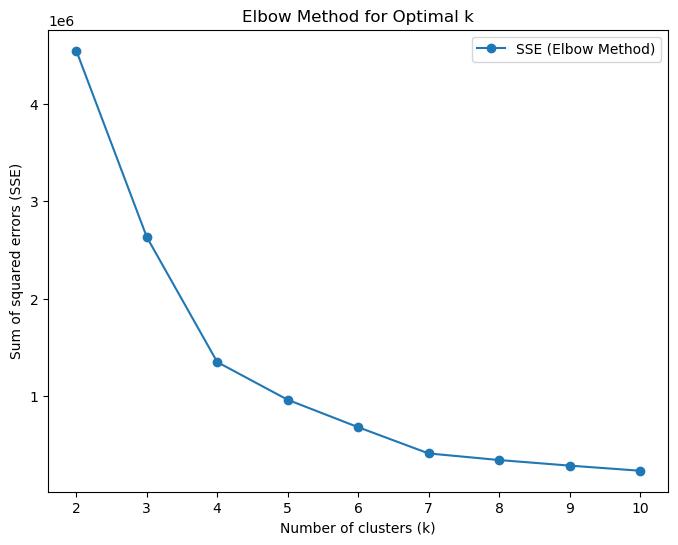

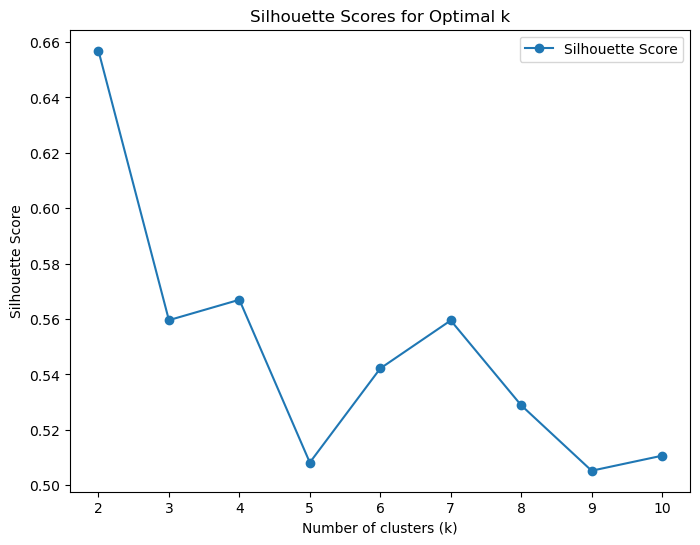

[4543749.614531862, 2633555.332409339, 1351749.369142808, 965019.0873703662, 684050.7480527543, 414997.5629249221, 347293.4895393583, 290111.64183758595, 237728.9703008799]
[0.6568536504294317, 0.5595823478987215, 0.5669477723599623, 0.5081797474674725, 0.5421550993884966, 0.5594856546979969, 0.5288559452839453, 0.5052248272657792, 0.5106480753751408]


In [73]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Initialize lists to store SSE and Silhouette scores
sse = []
silhouette_scores = []
k_values = range(2, 11)  # Range of k values to test

# Loop over k values to perform K-Means clustering
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans_labels = kmeans.fit_predict(data)  # Students should input the correct data

    # Append Sum of Squared Errors (SSE) for the Elbow Method
    sse.append(kmeans.inertia_)

    # Calculate and append Silhouette score for each k
    silhouette_avg = silhouette_score(data, kmeans_labels)
    silhouette_scores.append(silhouette_avg)

print('k_values', k_values)
print('sse', sse)
# print('silhouette_scores', silhouette_score)
# For autograder: store SSE and silhouette scores
step3_sse = sse
step3_silhouette_scores = silhouette_scores

# Plot SSE for Elbow Method
plt.figure(figsize=(8, 6))
plt.plot(k_values, sse, marker='o', label='SSE (Elbow Method)')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Sum of squared errors (SSE)')
plt.legend()
plt.show()

# Plot Silhouette Scores
plt.figure(figsize=(8, 6))
plt.plot(k_values, silhouette_scores, marker='o', label='Silhouette Score')
plt.title('Silhouette Scores for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.show()

print(sse)
print(silhouette_scores)

**Step 4: Choose Optimal Clusters and Apply Multiple Clustering Algorithms**
**Instructions:**
1. Based on your analysis of the Elbow and Silhouette score plots, select an optimal number of clusters.
2. Apply multiple clustering algorithms to observe the clustering patterns and compare their outcomes.

  * Algorithms to Implement:
    1. K-Means Clustering (using the optimal number of clusters)
    2. Agglomerative Clustering (using the optimal number of clusters)
   
3. Store the labels from each clustering method for further analysis.

In [74]:
# Import necessary libraries
from sklearn.cluster import KMeans, AgglomerativeClustering

# Set the optimal number of clusters (students should review previous steps to determine the optimal number of clusters)
optimal_k = 3

# K-Means Clustering
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_labels = kmeans.fit_predict(data)  # Students should input the correct dataset here

# Agglomerative Clustering
agg_clustering = AgglomerativeClustering(n_clusters=optimal_k)
agg_labels = agg_clustering.fit_predict(data)  # Students should input the correct dataset here

# For autograder
step4_kmeans_labels = kmeans_labels
step4_agg_labels = agg_labels

# Display first few results to verify clustering
print("K-Means Labels:", kmeans_labels[:10])
print("Agglomerative Labels:", agg_labels[:10])


K-Means Labels: [1 1 2 2 1 2 2 2 1 1]
Agglomerative Labels: [0 0 0 0 2 0 0 0 0 0]


**Step 5: Visualize Clusters from Multiple Clustering Algorithms**

**Instructions:**

1. Use PCA and t-SNE to reduce the dataset to two dimensions for visualization.
2. Plot the reduced data using the cluster labels from each clustering algorithm:
  * K-Means
  * Agglomerative Clustering

3. Store the transformed PCA and t-SNE data for each clustering method in step5_pca_data and step5_tsne_data.

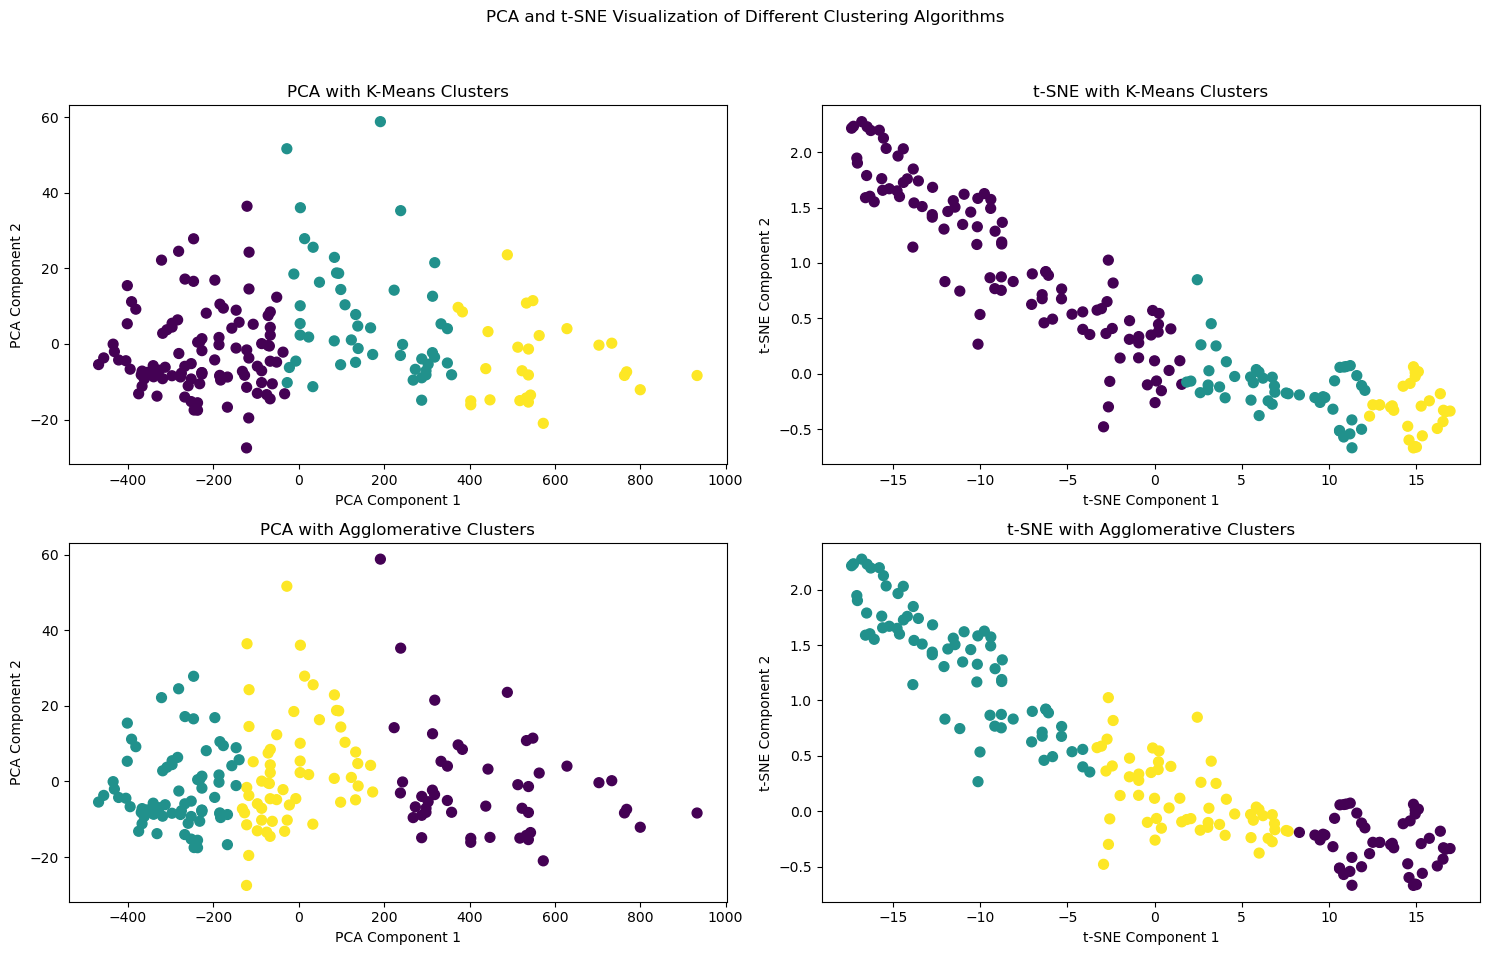

In [75]:
# Import necessary libraries
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# PCA and t-SNE transformations
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data)  # Students should input the correct dataset here
tsne = TSNE(n_components=2, random_state=42)
data_tsne = tsne.fit_transform(data)  # Students should input the correct dataset here

# For autograder
step5_pca_data = data_pca
step5_tsne_data = data_tsne

# Plotting setup
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("PCA and t-SNE Visualization of Different Clustering Algorithms")

# Plot PCA with K-Means Clusters
axes[0, 0].scatter(data_pca[:, 0], data_pca[:, 1], c=kmeans_labels, cmap='viridis', s=50)  # Students should use the correct labels (e.g., kmeans_labels)
axes[0, 0].set_title("PCA with K-Means Clusters")
axes[0, 0].set_xlabel("PCA Component 1")
axes[0, 0].set_ylabel("PCA Component 2")

# Plot t-SNE with K-Means Clusters
axes[0, 1].scatter(data_tsne[:, 0], data_tsne[:, 1], c=kmeans_labels, cmap='viridis', s=50)  # Students should use the correct labels
axes[0, 1].set_title("t-SNE with K-Means Clusters")
axes[0, 1].set_xlabel("t-SNE Component 1")
axes[0, 1].set_ylabel("t-SNE Component 2")

# Plot PCA with Agglomerative Clustering
axes[1, 0].scatter(data_pca[:, 0], data_pca[:, 1], c=agg_labels, cmap='viridis', s=50)  # Students should use the correct labels (e.g., agg_labels)
axes[1, 0].set_title("PCA with Agglomerative Clusters")
axes[1, 0].set_xlabel("PCA Component 1")
axes[1, 0].set_ylabel("PCA Component 2")

# Plot t-SNE with Agglomerative Clustering
axes[1, 1].scatter(data_tsne[:, 0], data_tsne[:, 1], c=agg_labels, cmap='viridis', s=50)  # Students should use the correct labels
axes[1, 1].set_title("t-SNE with Agglomerative Clusters")
axes[1, 1].set_xlabel("t-SNE Component 1")
axes[1, 1].set_ylabel("t-SNE Component 2")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


**Step 6: Internal Validation Metrics**
**Instructions:**

1. Compute Internal Validation Metrics:
  * Evaluate the quality of the clusters formed by each algorithm (K-Means, Agglomerative) using the following metrics:
    * Davies-Bouldin Index (DBI): Measures cluster separation and compactness; lower values indicate better-defined clusters.
    * Calinski-Harabasz Score (CH): Assesses the ratio of cluster separation to within-cluster compactness; higher scores indicate more defined clusters.
2. Calculate Scores for Each Clustering Algorithm:
  * K-Means and Agglomerative Clustering:
  Use the optimal number of clusters identified previously.
  Compute the Davies-Bouldin Index and Calinski-Harabasz Score for both algorithms.
  
Store Results for Autograder:
Store each metric with variable names for autograding:
step6_dbi_kmeans, step6_ch_kmeans, step6_dbi_agg, step6_ch_agg

Interpret Results:
Based on the DBI and CH values, compare the performance of each clustering algorithm.



In [81]:
# Import necessary libraries
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

# Calculate Davies-Bouldin and Calinski-Harabasz scores for K-Means and Agglomerative Clustering
dbi_kmeans = davies_bouldin_score(data, kmeans_labels)  # Students should input the correct dataset and labels for K-Means
dbi_agg = davies_bouldin_score(data, agg_labels)     # Students should input the correct dataset and labels for Agglomerative
ch_kmeans = calinski_harabasz_score(data, kmeans_labels) # Students should input the correct dataset and labels for K-Means
ch_agg = calinski_harabasz_score(data, agg_labels)    # Students should input the correct dataset and labels for Agglomerative


print('kmeans -> dbi: ', dbi_kmeans, ', ch: ', ch_kmeans)
print('agg -> dbi: ', dbi_agg, ', ch: ', ch_agg)

# For autograder
step6_dbi_kmeans = dbi_kmeans
step6_dbi_agg = dbi_agg
step6_ch_kmeans = ch_kmeans
step6_ch_agg = ch_agg
print('''\ninterpretation:\n
agglomeratives has lower DBI value, means it\'s clusters are slightly better separated, relative to internal spread. furthermore it has higher CH value, means strong ratio of between cluster to within cluster variance. So the conclusion is clear, on this dataset Agglomerative produces more compact and better separated clusters than k-means
'''
)

kmeans -> dbi:  0.549557597464291 , ch:  497.00487620805814
agg -> dbi:  0.5357343073560251 , ch:  552.851711505718

interpretation:

agglomeratives has lower DBI value, means it's clusters are slightly better separated, relative to internal spread. furthermore it has higher CH value, means strong ratio of between cluster to within cluster variance. So the conclusion is clear, on this dataset Agglomerative produces more compact and better separated clusters than k-means



# Part 2: Transition to Supervised Learning
**Objective**

Using the true labels in the complete dataset  (assignment3_data_with_labels.csv), evaluate how the previously found clusters align with actual species. Prepare the data for supervised learning.


**Step 7: Provide the True Labels**

**Instructions:**

1. Load the dataset with labels from assignment3_data_with_labels.csv.
2. Extract the true_label column and store it in step7_true_labels for evaluation purposes.

In [82]:
# Import necessary library
import pandas as pd

# Load the dataset from 'assignment3_data_with_labels.csv'
data_with_labels = pd.read_csv('assignment3_data_with_labels.csv')

print('columns:\n', data_with_labels.columns.tolist())
print('count:\n', data_with_labels.value_counts())

# For autograder: Assign the true labels to the expected variable
step7_true_labels = data_with_labels['true_label']  # Students should complete by selecting the 'true_label' column


columns:
 ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'true_label']
count:
 alcohol  malic_acid  ash   alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue   od280/od315_of_diluted_wines  proline  true_label
11.03    1.51        2.20  21.5               85.0       2.46           2.17        0.52                  2.01             1.90             1.71  2.87                          407.0    1             1
13.68    1.83        2.36  17.2               104.0      2.42           2.69        0.42                  1.97             3.84             1.23  2.87                          990.0    0             1
13.40    3.91        2.48  23.0               102.0      1.80           0.75        0.43                  1.41             7.30             0.70  1.56          

**Step 8: Cluster Evaluation with True Labels**

**Instructions:**

1. Compare clustering results with true labels using ARI and NMI for each clustering algorithm.
2. Generate and visualize confusion matrices for each clustering algorithm to assess alignment with actual classes.
3. Store ARI and NMI values for K-Means and Agglomerative Clustering in step8_ari_kmeans, step8_nmi_kmeans, step8_ari_agg, and step8_nmi_agg.

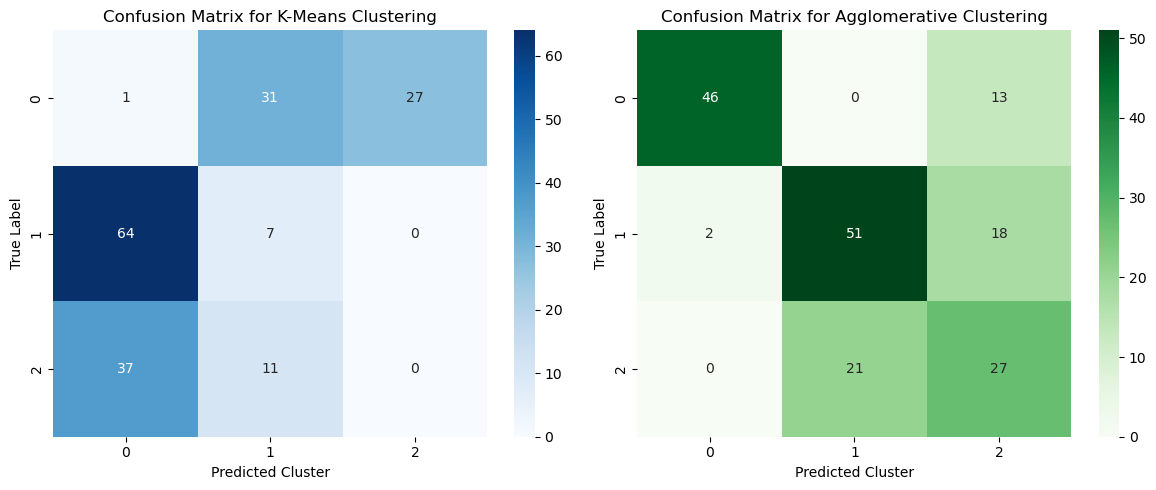

In [83]:
# Import necessary libraries
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate Adjusted Rand Index and Normalized Mutual Information for K-Means
ari_kmeans = adjusted_rand_score(step7_true_labels, kmeans_labels)  # Complete by calling adjusted_rand_score with true and predicted labels
nmi_kmeans = normalized_mutual_info_score(step7_true_labels, kmeans_labels)  # Complete by calling normalized_mutual_info_score

# Calculate Adjusted Rand Index and Normalized Mutual Information for Agglomerative Clustering
ari_agg = adjusted_rand_score(step7_true_labels, agg_labels)  # Complete by calling adjusted_rand_score
nmi_agg = normalized_mutual_info_score(step7_true_labels, agg_labels)  # Complete by calling normalized_mutual_info_score

# Store results for autograder
step8_ari_kmeans = ari_kmeans
step8_nmi_kmeans = nmi_kmeans
step8_ari_agg = ari_agg
step8_nmi_agg = nmi_agg

# Generate and visualize confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# K-Means Confusion Matrix
cm_kmeans = confusion_matrix(step7_true_labels, kmeans_labels)  # Students complete with true and K-Means labels
sns.heatmap(cm_kmeans, annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion Matrix for K-Means Clustering")
ax[0].set_xlabel("Predicted Cluster")
ax[0].set_ylabel("True Label")

# Agglomerative Clustering Confusion Matrix
cm_agg = confusion_matrix(step7_true_labels, agg_labels)  # Students complete with true and Agglomerative labels
sns.heatmap(cm_agg, annot=True, fmt="d", cmap="Greens", ax=ax[1])
ax[1].set_title("Confusion Matrix for Agglomerative Clustering")
ax[1].set_xlabel("Predicted Cluster")
ax[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()


**Step 9: Data Preprocessing and Class Imbalance Check**

**Instructions:**

1. Standardize the features using StandardScaler.
2. Check for class imbalance by examining the distribution of true labels. Store the distribution in step9_class_distribution for easy review.
3. Store the scaled dataset in step9_data_scaled.

In [84]:
# Import necessary library
from sklearn.preprocessing import StandardScaler

# Standardizing the features
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_with_labels.drop('true_label', axis=1)) # Complete by applying scaler to the features, excluding the 'true_label' column

# Convert back to DataFrame
data_scaled = pd.DataFrame(data_scaled, columns=data_with_labels.drop('true_label', axis=1).columns)  # Complete with feature column names

# For autograder: store the scaled data
step9_data_scaled = data_scaled

# Check for class imbalance
class_distribution = data_with_labels['true_label'].value_counts(normalize=True)  # Complete with value counts for 'true_label', normalized to see distribution
print("Class Distribution:\n", class_distribution)

# For autograder
step9_class_distribution = class_distribution


Class Distribution:
 true_label
1    0.398876
0    0.331461
2    0.269663
Name: proportion, dtype: float64


**Step 10: Train-Test Split**

**Instructions:**

1. Split the data into training and testing sets:
Use 70% of the data for training and 30% for testing.
2. Ensure the split maintains the distribution of the target labels (stratified split if applicable).
3. Store the resulting X_train, X_test, y_train, and y_test variables in step10_X_train, step10_X_test, step10_y_train, and step10_y_test for autograding.

In [85]:
# Import necessary library
from sklearn.model_selection import train_test_split

# Define features and target variable
X = data_scaled  # Complete by assigning the scaled data (data_scaled) as features
y = data_with_labels['true_label']  # Complete by assigning 'true_label' from data_with_labels as target variable

# Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # Complete by filling in X and y

# For autograder
step10_X_train = X_train
step10_X_test = X_test
step10_y_train = y_train
step10_y_test = y_test

# Display shapes (not for autograder)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)





Training data shape: (124, 13)
Testing data shape: (54, 13)


# Part 3: Neural Network Implementation
**Step 11: Construct the Neural Network Architecture**

**Objective:** Define the architecture for a neural network that is well-suited for multi-class classification with a provided dataset.

**Instructions:**

1. Define the Architecture: Build a neural network with at least three hidden layers, reducing the number of neurons in each subsequent layer to help the model learn complex representations.
Layer structure:
* Layer 1: 128 neurons
* Layer 2: 64 neurons
* Layer 3: 32 neurons
2. Activation Functions:Use ReLU activation for all hidden layers.
3. Output Layer: Use a linear layer for the output with the number of neurons equal to the number of classes. This output will be used with categorical cross-entropy loss, which internally applies softmax.
4. Regularization Techniques: Add dropout layers after each hidden layer with a dropout rate of 0.5 to prevent overfitting.
5. Initialize the Model: Set input size, output size, and define the model structure using a NeuralNet class.

In [138]:
# Import necessary libraries
import torch
import torch.nn as nn
import numpy as np
import random

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Define the neural network architecture
class NeuralNet(nn.Module):
    def __init__(self, input_size, output_size):
        super(NeuralNet, self).__init__()

        # Define layers according to instructions
        self.fc1 = nn.Linear(input_size, 128)       # Layer 1: Replace with 128 neurons
        self.fc2 = nn.Linear(128, 64)              # Layer 2: Replace with 64 neurons
        self.fc3 = nn.Linear(64, 32)              # Layer 3: Replace with 32 neurons
        self.output = nn.Linear(32, output_size)   # Output layer: Match Layer 3 output size

        # Dropout layer for regularization
        self.dropout = nn.Dropout(0.5)  # Define dropout rate (e.g., 0.5)

    def forward(self, x):
        # Apply ReLU and dropout as instructed
        x = torch.relu(self.fc1(x))     # ReLU for Layer 1
        x = self.dropout(x)             # Dropout after Layer 1
        x = torch.relu(self.fc2(x))     # ReLU for Layer 2
        x = self.dropout(x)             # Dropout after Layer 2
        x = torch.relu(self.fc3(x))     # ReLU for Layer 3
        x = self.dropout(x)             # Dropout after Layer 3 # added this as it's asked to add dropout after each and every hidden layer
        x = self.output(x)              # Output layer (linear)
        return x

# Initialize the model with input and output sizes as instructed
input_size = X_train.shape[1]  # Define based on features
output_size = len(np.unique(y))  # Define based on unique classes
model = NeuralNet(input_size=input_size, output_size=output_size)

# Display the model structure for verification
model_structure = str(model)
print(model_structure)  # Verify model structure matches instructions

# For autograder:
step11_model_structure = model_structure


NeuralNet(
  (fc1): Linear(in_features=13, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (output): Linear(in_features=32, out_features=3, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


**Step 12: Train the Model**

**Objective:** Train the constructed model on the training dataset, implementing early stopping to monitor and control overfitting.

**Instructions:**

1. Set Up DataLoader: Convert X_train and y_train to PyTorch tensors and load them into a DataLoader with a batch size of 32.

2. Define the Loss Function and Optimizer:
  * Use categorical cross-entropy (nn.CrossEntropyLoss) as the loss function for multi-class classification.
  * Use Adam as the optimizer with a learning rate of 0.001.

4. Training Loop with Early Stopping:
  * Train the model over a set number of epochs (50).
  * Implement early stopping with a patience of 5 epochs, where training stops if validation loss does not improve for 5 consecutive epochs.
  * Save the best model state to restore later if early stopping is triggered.



In [127]:
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Set up DataLoader without shuffling
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)  # Convert X_train to torch tensor with dtype=torch.float32
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)  # Convert y_train to torch tensor with dtype=torch.long
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=False)  # Set batch size to 32

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Set learning rate

# Initialize lists to store losses per epoch for tracking
training_losses = []
validation_losses = []

# Training loop with early stopping parameters
epochs = 50
patience = 5
min_val_loss = float('inf')
epochs_no_improve = 0

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    # Training pass
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Calculate and record average training loss for the epoch
    avg_train_loss = running_loss / len(train_loader)
    training_losses.append(avg_train_loss)

    # Validation pass (using X_train_tensor, y_train_tensor as a validation set)
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_train_tensor)
        val_loss = criterion(val_outputs, y_train_tensor).item()
    validation_losses.append(val_loss)

    # Early stopping check
    if val_loss < min_val_loss:
        min_val_loss = val_loss
        epochs_no_improve = 0
        best_model_state = model.state_dict()  # Save best model state
    else:
        epochs_no_improve += 1
        if epochs_no_improve == patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

# Restore the best model state
model.load_state_dict(best_model_state)

# Capture the best validation loss for the grader
best_validation_loss = min_val_loss
print(f"Best Validation Loss after Early Stopping: {best_validation_loss}")

# Grader Outputs:
step12_best_validation_loss = best_validation_loss
step12_final_training_loss = avg_train_loss  # Final training loss after the last epoch
step12_training_losses = training_losses  # List of training losses per epoch for Step 17
step12_validation_losses = validation_losses  # List of validation losses per epoch for Step 17


Best Validation Loss after Early Stopping: 0.0031188104767352343


**Step 13: Evaluate the Model**

**Instructions:**

1. Evaluate the model on the test set using the following metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC (One-vs-Rest) if multi-class.
2. Generate a confusion matrix and classification report to assess model performance.


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.95      0.98        21
           2       0.93      1.00      0.97        14

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



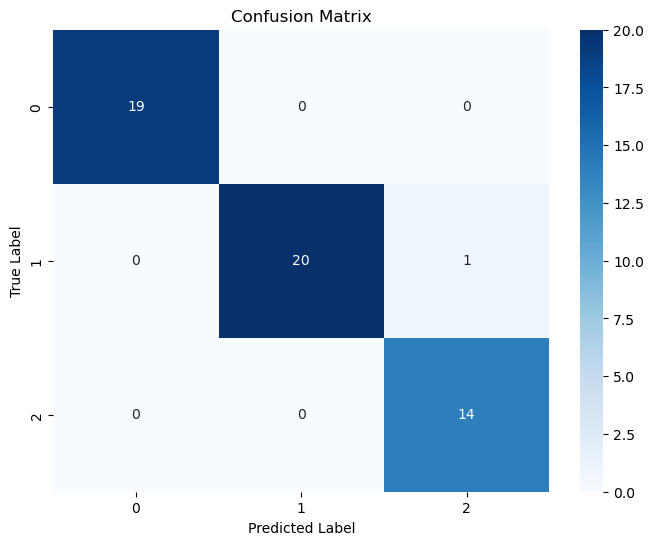

In [128]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare test data
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)  # Convert X_test to tensor with dtype=torch.float32
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)  # Convert y_test to tensor with dtype=torch.long

# Model evaluation
model.eval()
with torch.no_grad():
    y_pred_proba = F.softmax(model(X_test_tensor), dim=1).numpy()  # Get model's probability outputs
    y_pred = np.argmax(y_pred_proba, axis=1)  # Convert probabilities to predicted labels

# Generate Classification Report and Metrics Calculation
print("Classification Report:")
report = classification_report(y_test, y_pred)  # Replace with y_test and y_pred
print(report)

# Calculate metrics based on test set predictions
accuracy = accuracy_score(y_test, y_pred)  # Replace with y_test and y_pred
precision = precision_score(y_test, y_pred, average='weighted')  # Replace with y_test and y_pred
recall = recall_score(y_test, y_pred, average='weighted')  # Replace with y_test and y_pred
f1 = f1_score(y_test, y_pred, average='weighted')  # Replace with y_test and y_pred

# ROC-AUC Score (One-vs-Rest) for multi-class
try:
    roc_auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average='weighted')  # Replace with y_test and y_pred_proba
except ValueError:
    roc_auc = None  # Handle case when ROC-AUC cannot be computed

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)  # Replace with y_test and y_pred
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))  # Replace with y_test
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Outputs for Grading
step13_accuracy = accuracy
step13_precision = precision
step13_recall = recall
step13_f1_score = f1
step13_roc_auc = roc_auc
step13_confusion_matrix = cm


# Part 4: Hyperparameter Tuning and Cross-Validation

**Step 14:**

**Objective:** Compare the performance of a fixed model configuration to ensure consistent results across students.

**Instructions:**

1. Fixed Configuration: Use the following fixed hyperparameters for tuning:

* Number of hidden layers: 3
* Neurons per layer: 128 in the first layer, 64 in the second layer, and 32 in the third layer
* Activation function: ReLU for all hidden layers and softmax for the output layer
* Learning rate: 0.001
* Optimizer: Adam
* Dropout rate: 0.5 after each hidden layer
* Batch size: 32

2. Training and Validation:
* Train the model with this configuration for up to 50 epochs, using early stopping with a patience of 5 epochs.
* Monitor the validation loss, and at the end of training, restore the model weights from the epoch with the lowest validation loss.
3. Record Performance:
* Document the validation loss and accuracy after training with this configuration.

Note: Use the same random seed for all steps to ensure consistent training behavior.

In [129]:
from sklearn.model_selection import ParameterGrid
import torch.optim as optim

# Set up DataLoader
train_loader = DataLoader(dataset=TensorDataset(X_train_tensor, y_train_tensor), 
                          batch_size=32, shuffle=False)  # Replace with appropriate dataset and batch size

# Initialize variables to track best results
best_params = None
best_score = float('inf')
epochs = 50
patience = 5
best_overall_model_state = None


param_grid = {
    'learning_rate': [0.001],
    'batch_size': [32],
    'drop_out_rate': [0.5]
}

# Loop over fixed parameter grid
for params in ParameterGrid(param_grid):  # Replace with fixed parameter grid
    # Set optimizer with learning rate from params
    model = NeuralNet(input_size, output_size)  # reinitialize per config
    torch.manual_seed(42)
    optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'])
    min_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None
    
    # Training loop with early stopping
    for epoch in range(epochs):  # Set the number of epochs
        model.train()
        running_loss = 0.0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)  # Define your loss function here
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        # Validation step
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_train_tensor)  # Replace with appropriate validation data
            val_loss = criterion(val_outputs, y_train_tensor).item()  # Define validation loss calculation here

        # Early stopping logic
        if val_loss < min_val_loss:
            min_val_loss = val_loss
            epochs_no_improve = 0
            best_model_state = model.state_dict()
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping at epoch {epoch+1}")
                break


    model.eval()
    with torch.no_grad():
        val_outputs = model(X_train_tensor)
        val_preds = torch.argmax(val_outputs, dim=1)
        val_accuracy = accuracy_score(y_train_tensor.numpy(), val_preds.numpy())
    print(f"Config {params} : Val Loss: {min_val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}")
    
    # Update best score if current configuration is better
    if min_val_loss < best_score:
        best_score = min_val_loss
        best_params = params
        best_overall_model_state = best_model_state

# Load the best model state
model.load_state_dict(best_overall_model_state)
best_validation_loss = best_score

best_tuned_model_state = model.state_dict()

# Record final validation loss
print(f"Best Validation Loss after tuning: {best_validation_loss}")

# Grader Outputs
step14_best_validation_loss = best_validation_loss
step14_best_params = best_params
step14_best_val_accuracy = val_accuracy


Config {'batch_size': 32, 'drop_out_rate': 0.5, 'learning_rate': 0.001} : Val Loss: 0.0036, Val Accuracy: 1.0000
Best Validation Loss after tuning: 0.0035957389045506716


**Step 15: Cross-Validation**

**Implement k-fold cross-validation:**
1. Use a 5-fold cross-validation approach to evaluate model stability. Set random_state=42 for reproducibility.
Record cross-validation scores:
2. Calculate and store the validation accuracy score for each fold. Report the average accuracy across all folds as a measure of model stability.
3. Reflect on cross-validation's benefits: Discuss how cross-validation helps ensure the model's robustness and supports its ability to generalize effectively across different subsets of data.


In [132]:
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
import numpy as np
import torch.optim as optim
import torch

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# K-fold Cross-Validation with fixed parameters
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)  # Set appropriate random state for reproducibility
cross_val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X.values)):  # Split data appropriately
    # Reset the random seed before each fold
    torch.manual_seed(42)

    # Split into train and validation sets for this fold
    X_fold_train, X_fold_val = X.values[train_index], X.values[val_index]
    y_fold_train, y_fold_val = y.values[train_index], y.values[val_index]

    # Convert to PyTorch tensors
    X_fold_train_tensor = torch.tensor(X_fold_train, dtype=torch.float32)
    y_fold_train_tensor = torch.tensor(y_fold_train, dtype=torch.long)
    X_fold_val_tensor = torch.tensor(X_fold_val, dtype=torch.float32)
    y_fold_val_tensor = torch.tensor(y_fold_val, dtype=torch.long)

    # Initialize a new model with the same architecture for each fold
    model = NeuralNet(input_size, output_size)  # Instantiate the neural network model
    optimizer = optim.Adam(model.parameters(), lr=0.001)  # Set learning rate
    criterion = nn.CrossEntropyLoss()

    # Train the model on the fold training data
    for epoch in range(100):  # Define the number of epochs
        model.train()
        optimizer.zero_grad()
        outputs = model(X_fold_train_tensor)
        loss = criterion(outputs, y_fold_train_tensor)
        loss.backward()
        optimizer.step()

    # Calculate validation accuracy for this fold
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_fold_val_tensor)
        val_preds = torch.argmax(val_outputs, axis=1)
        val_accuracy = accuracy_score(y_fold_val_tensor, val_preds)
        cross_val_scores.append(val_accuracy)

# Cross-validation results
step15_cross_val_scores = cross_val_scores
step15_mean_cv_score = np.mean(cross_val_scores)
print(f"{k}-Fold Cross-Validation Scores:", cross_val_scores)
print("Mean Cross-Validation Score:", step15_mean_cv_score)
print('''\ndiscussion:\n
5-fold cross validation tested the model on five different data partitions. 
it uses every partition for validation only once as we know. 
the fold accuracies were (1.0, 0.9722222222222222, 0.9722222222222222, 0.9428571428571428, 1.0) 
and cluster gives a mean score of 0.9774603174603176. 
it says the performance doesn't depend on any random train-test split. 
this is a direct evidence of robustness of the algorithm; model generalizes across different 
subsets rather than fitting to one partition. 
''')

5-Fold Cross-Validation Scores: [1.0, 0.9722222222222222, 0.9722222222222222, 0.9428571428571428, 1.0]
Mean Cross-Validation Score: 0.9774603174603176

discussion:

5-fold cross validation tested the model on five different data partitions. 
it uses every partition for validation only once as we know. 
the fold accuracies were (1.0, 0.9722222222222222, 0.9722222222222222, 0.9428571428571428, 1.0) 
and cluster gives a mean score of 0.9774603174603176. 
it says the performance doesn't depend on any random train-test split. 
this is a direct evidence of robustness of the algorithm; model generalizes across different 
subsets rather than fitting to one partition. 



# Part 5: Quantitative Comparison

**Objective**

Compare the performance of different models quantitatively and discuss their applicability.

**Step 16: Clustering vs. Classification Metrics Comparison**

**Instructions:**

1. Compare the clustering results with classification results using:
  * Adjusted Rand Index, Normalized Mutual Information (for clustering)
  * Accuracy, Precision, Recall, F1-Score, ROC-AUC (for classification)
2. Present the metrics in a summary table for both unsupervised and supervised learning models.


In [133]:
import torch.nn.functional as F
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model = NeuralNet(input_size, output_size)
model.load_state_dict(best_tuned_model_state)
model.eval()

# Define y_true based on y_test
y_true = y_test  # Define this based on y_test (true labels for the test set)

# Model evaluation
model.eval()
with torch.no_grad():
    # Apply softmax to get probability outputs
    y_pred_proba_classification = F.softmax(model(X_test_tensor), dim=1).numpy()  # Fill with X_test_tensor
    y_pred_classification = np.argmax(y_pred_proba_classification, axis=1)

# Classification Metrics
accuracy_classification = accuracy_score(y_true, y_pred_classification)
precision_classification = precision_score(y_true, y_pred_classification, average='weighted')
recall_classification = recall_score(y_true, y_pred_classification, average='weighted')
f1_classification = f1_score(y_true, y_pred_classification, average='weighted')

# ROC-AUC Score (Handle exception if not applicable)
try:
    roc_auc_classification = roc_auc_score(y_true, y_pred_proba_classification, multi_class='ovr', average='weighted')
except ValueError:
    roc_auc_classification = None

# Clustering Metrics (from previous steps)
ari_clustering = ari_kmeans  # Adjusted Rand Index from previous clustering step
nmi_clustering = nmi_kmeans  # Normalized Mutual Information from previous clustering step

# Summary Table
summary_table = pd.DataFrame({
    'Metric': ['Adjusted Rand Index', 'Normalized Mutual Information', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Clustering': [ari_clustering, nmi_clustering, None, None, None, None, None],
    'Classification': [None, None, accuracy_classification, precision_classification, recall_classification, f1_classification, roc_auc_classification]
})

print(summary_table)
step16_summary_table = summary_table  # For autograder
print('''\nDiscussion:\nthe table shows a clear performance gap between the two approaches, 
the unsupervised cluster achieved moderate agreement with the true classes (ARI, NMI), 
indicating it recovered real but imperfect structure in the data. the supervised classifier 
in contrast performs far bette,r reacing ~0.98 across accuracy, precision, recall, F1 scores with ROC-AUC of 1.0
this reflects the classfier's access to true labels and its use of standadised features,
whereas the clustering ran on raw, unscaled data dominated by high-magnitude features when 
labels are unavailable, while classification exploits known labels for accurate predictions.
'''
)

                          Metric  Clustering  Classification
0            Adjusted Rand Index    0.351772             NaN
1  Normalized Mutual Information    0.423309             NaN
2                       Accuracy         NaN        0.981481
3                      Precision         NaN        0.982716
4                         Recall         NaN        0.981481
5                       F1-Score         NaN        0.981575
6                        ROC-AUC         NaN        1.000000

Discussion:
the table shows a clear performance gap between the two approaches, 
the unsupervised cluster achieved moderate agreement with the true classes (ARI, NMI), 
indicating it recovered real but imperfect structure in the data. the supervised classifier 
in contrast performs far bette,r reacing ~0.98 across accuracy, precision, recall, F1 scores with ROC-AUC of 1.0
this reflects the classfier's access to true labels and its use of standadised features,
whereas the clustering ran on raw, unscaled dat

**Step 17: Model Performance Visualization**

**Instructions:**

1. Plot Training vs Validation Loss: To analyze model overfitting or underfitting.
2. Visualize Confusion Matrices as Heatmaps for better insights into model predictions.
3. Discuss any observed patterns, such as potential class imbalance or overfitting issues.

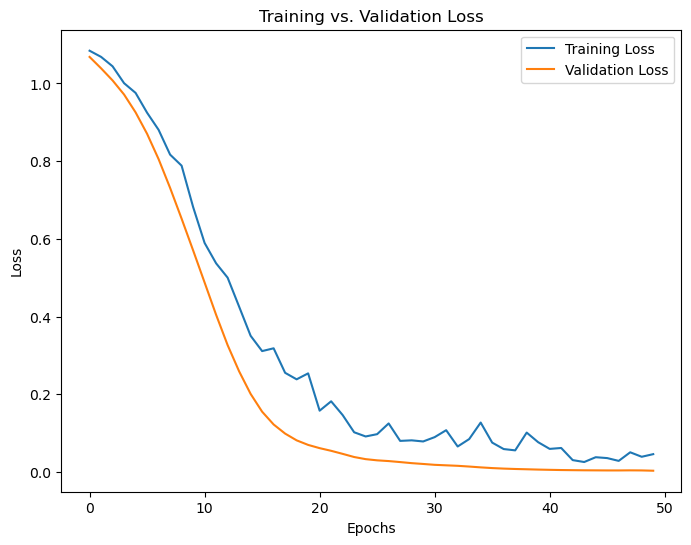

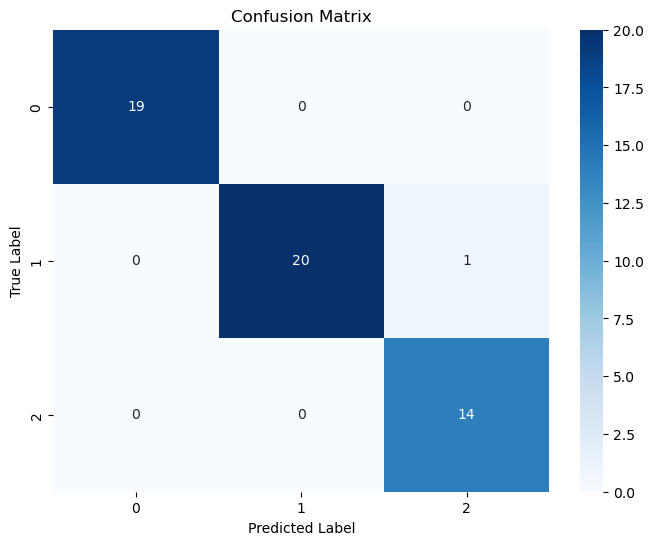

conf_matrix [[19  0  0]
 [ 0 20  1]
 [ 0  0 14]]
validation_losses [1.0682032108306885, 1.0388667583465576, 1.0076792240142822, 0.9713525176048279, 0.9254692792892456, 0.8702890276908875, 0.8051281571388245, 0.7310842275619507, 0.6518898010253906, 0.5703319907188416, 0.4875018894672394, 0.4044041931629181, 0.3264763057231903, 0.25892820954322815, 0.20084397494792938, 0.1550394743680954, 0.12214703857898712, 0.09867027401924133, 0.08129778504371643, 0.06956800818443298, 0.061229508370161057, 0.05436854064464569, 0.04651626944541931, 0.03838816285133362, 0.032915424555540085, 0.029834726825356483, 0.027958635240793228, 0.025371123105287552, 0.022630706429481506, 0.020509975031018257, 0.018295077607035637, 0.01701047271490097, 0.01575404219329357, 0.013852682895958424, 0.011734864674508572, 0.00992698036134243, 0.008585368283092976, 0.007592192851006985, 0.0068403929471969604, 0.006051396951079369, 0.005418763961642981, 0.004871436394751072, 0.004528909921646118, 0.00421997020021081, 0.00

In [136]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, confusion_matrix
import seaborn as sns
import numpy as np

# Ensure training and validation loss tracking (assuming you captured these in Step 12)
# Example: Fill in training_losses and validation_losses lists during training

# 1. Training vs Validation Loss Plot
plt.figure(figsize=(8, 6))
plt.plot(training_losses, label='Training Loss')  # Replace with training_losses
plt.plot(validation_losses, label='Validation Loss')  # Replace with validation_losses
plt.title('Training vs. Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 2. Confusion Matrix Visualization
conf_matrix = confusion_matrix(y_test, y_pred_classification)  # Replace with (y_test, y_pred_classification)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))  # Replace with y_test
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Grader Outputs
step17_training_losses = training_losses  # Replace with training_losses
step17_validation_losses = validation_losses  # Replace with validation_losses
step17_confusion_matrix = conf_matrix

print('conf_matrix', conf_matrix)
print('validation_losses', validation_losses)
print('training_losses', training_losses)
print('''\n\ndiscussion:\n
training and validation loss curves both decrease steadily across all 50 epoches, 
and remains closely aligned with no point where validation loss rises
while training continues to fall.
this is a sign of no overfitting. 
the dropout regularisation and feature standardization effectively controlled variance.
the confusion matrix is almost diagonal with 19, 20, and 14 samples correctly classified for 
all 3 classes with only a single misclassificaiton. eventhough the dataset has class imbalance, 
the model performs equally well across all three classes
''')